<a href="https://colab.research.google.com/github/jpgattey-code/Milestone-2/blob/main/Milestone2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd

# 1. Replace 'your_file_name.csv' with the name of your uploaded file
file_path = 'ChampData.csv'

# 2. Read the file into a variable named 'df'
try:
    df = pd.read_csv(file_path)
    print("Success! Your CSV dataset is loaded into the variable 'df'.")

    # 3. Show the first 5 rows of your data
    display(df.head())
except FileNotFoundError:
    print(f"Could not find a file named '{file_path}'. Please make sure you uploaded it to the left sidebar and spelled the name correctly!")



Success! Your CSV dataset is loaded into the variable 'df'.


,Champion Name,WR (Global),PR (Global),WR (NA),PR (NA),WR (KR),PR (KR),WR (EUW),PR (EUW),WR (JPN),PR (JPN)
0,Aatrox,49.43%,5.12%,49.31%,3.94%,49.31%,6.57%,3.34%,4.07%,49.87%,8.64%
1,Ahri,50.84%,8.97%,50.35%,10.06%,50.44%,8.96%,50.89%,10.75%,48.77%,11.91%
2,Akali,48.34%,6.70%,48.58%,5.83%,49.08%,8.92%,48.33%,6.10%,48.89%,8.19%
3,Akshan,48.37%,1.75%,48.10%,2.42%,49.31%,1.13%,49.12%,2.55%,49.04%,1.22%
4,Alistar,50.85%,3.74%,51.60%,3.81%,51.58%,4.80%,50.59%,3.59%,50.31%,4.82%


In [ ]:
try:
    # 1. See columns, data types, and non-null (non-missing) counts
    print("=== Column Info and Data Types ===")
    df.info()
    print("\n")

    # 2. Find the total number of missing values (null values) in each column
    print("=== Missing Values per Column ===")
    missing_values = df.isnull().sum()
    display(missing_values)
    print("\n")

    # 3. Count the number of duplicate rows in the entire dataset
    print("=== Duplicate Rows ===")
    duplicates_count = df.duplicated().sum()
    print(f"There are {duplicates_count} duplicate rows in this dataset.")
except NameError:
    print("Variable 'df' is not defined yet. Please run one of the options in Step 1 to successfully load your dataset first!")

=== Column Info and Data Types ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Champion Name  172 non-null    object
 1   WR (Global)    172 non-null    object
 2   PR (Global)    172 non-null    object
 3   WR (NA)        172 non-null    object
 4   PR (NA)        172 non-null    object
 5   WR (KR)        172 non-null    object
 6   PR (KR)        172 non-null    object
 7   WR (EUW)       172 non-null    object
 8   PR (EUW)       172 non-null    object
 9   WR (JPN)       172 non-null    object
 10  PR (JPN)       172 non-null    object
dtypes: object(11)
memory usage: 14.9+ KB


=== Missing Values per Column ===


,0
Champion Name,0
WR (Global),0
PR (Global),0
WR (NA),0
PR (NA),0
WR (KR),0
PR (KR),0
WR (EUW),0
PR (EUW),0
WR (JPN),0




=== Duplicate Rows ===
There are 0 duplicate rows in this dataset.


In [ ]:
import pandas as pd

# Configure pandas to display all rows
pd.set_option('display.max_rows', None)

# Display the entire DataFrame
display(df)

,Champion Name,WR (Global),PR (Global),WR (NA),PR (NA),WR (KR),PR (KR),WR (EUW),PR (EUW),WR (JPN),PR (JPN)
0,Aatrox,49.43%,5.12%,49.31%,3.94%,49.31%,6.57%,3.34%,4.07%,49.87%,8.64%
1,Ahri,50.84%,8.97%,50.35%,10.06%,50.44%,8.96%,50.89%,10.75%,48.77%,11.91%
2,Akali,48.34%,6.70%,48.58%,5.83%,49.08%,8.92%,48.33%,6.10%,48.89%,8.19%
3,Akshan,48.37%,1.75%,48.10%,2.42%,49.31%,1.13%,49.12%,2.55%,49.04%,1.22%
4,Alistar,50.85%,3.74%,51.60%,3.81%,51.58%,4.80%,50.59%,3.59%,50.31%,4.82%
5,Ambessa,48.33%,2.27%,48.03%,2.04%,48.43%,2.73%,47.97%,2.04%,48.92%,5.46%
6,Amumu,52.22%,3.66%,51.74%,5.00%,51.02%,2.70%,52.55%,4.33%,52.29%,2.44%
7,Anivia,50.00%,1.65%,49.60%,1.82%,50.66%,1.83%,49.96%,1.73%,47.82%,2.11%
8,Annie,49.98%,1.71%,49.27%,2.21%,51.24%,1.26%,49.97%,1.92%,48.13%,0.96%
9,Aphelios,49.70%,6.41%,49.58%,5.61%,50.06%,9.26%,49.64%,5.47%,49.38%,11.03%


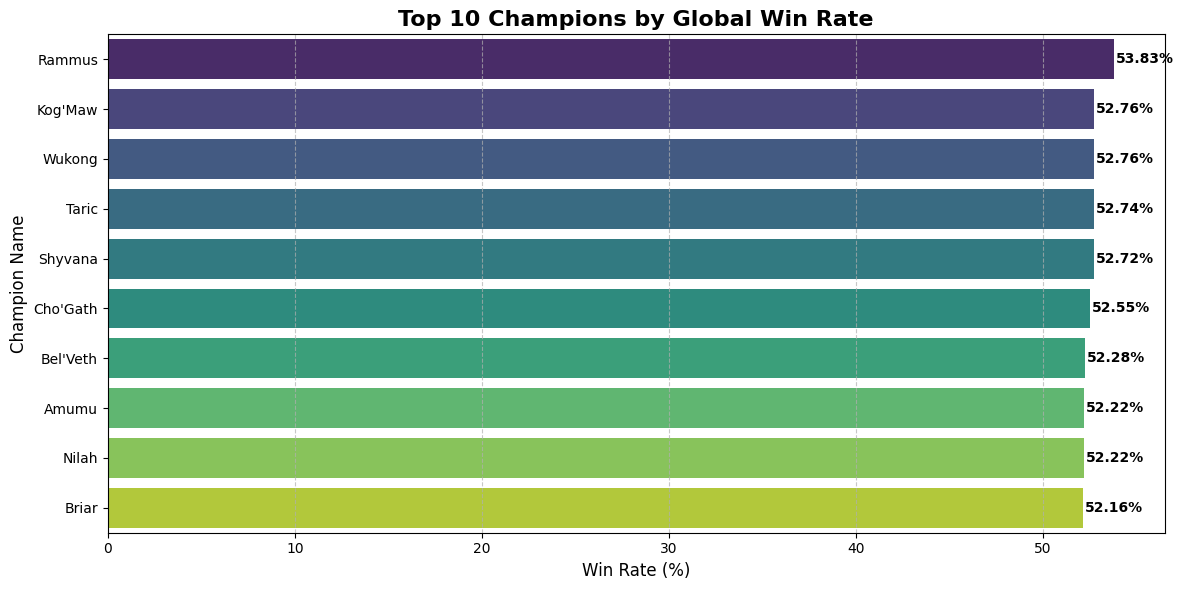

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is loaded
try:
    df
except NameError:
    file_path = 'ChampData.csv'
    df = pd.read_csv(file_path)

# 1. Clean the win rate columns by converting them from string percentages to numeric floats
df_clean = df.copy()

# List of all win rate columns to clean
wr_columns = ['WR (Global)', 'WR (NA)', 'WR (KR)', 'WR (EUW)', 'WR (JPN)']

for col in wr_columns:
    if col in df_clean.columns:
        # Remove percentage signs and convert to float
        df_clean[col] = df_clean[col].astype(str).str.rstrip('%').astype('float')

# 2. Get the top 10 champions by WR (Global)
top_10_champs = df_clean.nlargest(10, 'WR (Global)')

# 3. Create the bar chart
plt.figure(figsize=(12, 6))
sns.barplot(x='WR (Global)', y='Champion Name', data=top_10_champs, palette='viridis', hue='Champion Name', legend=False)

# Add details to the plot
plt.title('Top 10 Champions by Global Win Rate', fontsize=16, fontweight='bold')
plt.xlabel('Win Rate (%)', fontsize=12)
plt.ylabel('Champion Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Display the value labels on each bar
for index, value in enumerate(top_10_champs['WR (Global)']):
    plt.text(value + 0.1, index, f'{value:.2f}%', va='center', fontweight='semibold')

plt.tight_layout()
plt.show()

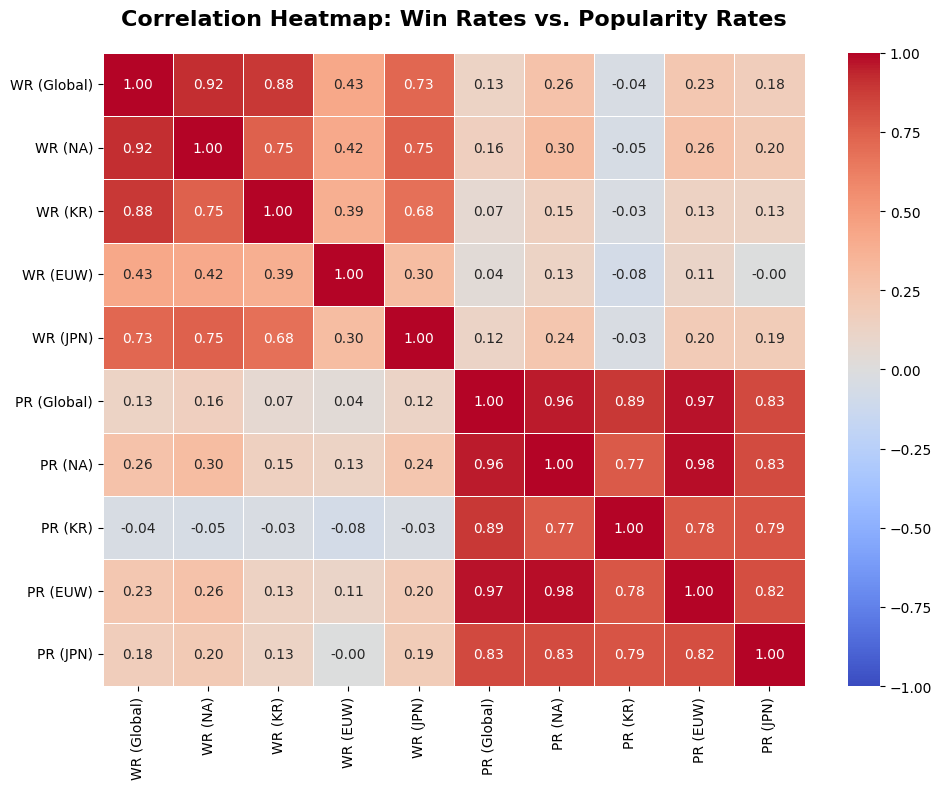

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is loaded
try:
    df
except NameError:
    file_path = 'ChampData.csv'
    df = pd.read_csv(file_path)

# Create a copy of the dataframe to clean
df_corr = df.copy()

# Identify all Win Rate and Popularity Rate columns
wr_cols = [c for c in df_corr.columns if 'WR' in c]
pr_cols = [c for c in df_corr.columns if 'PR' in c]

# Clean both WR and PR columns by removing '%' and converting to float
for col in wr_cols + pr_cols:
    if col in df_corr.columns:
        df_corr[col] = df_corr[col].astype(str).str.rstrip('%').astype('float')

# Select only the cleaned numeric columns for correlation
numeric_df = df_corr[wr_cols + pr_cols]

# Compute the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap: Win Rates vs. Popularity Rates', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

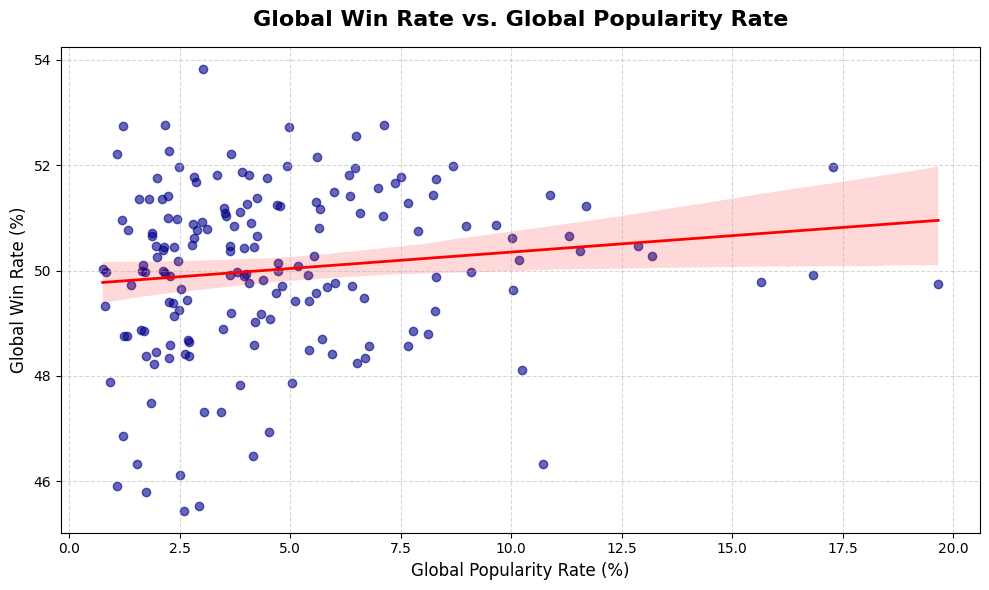

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Using df_corr which already has clean numeric values for WR and PR
plt.figure(figsize=(10, 6))

# Create scatter plot with trendline
sns.regplot(
    x='PR (Global)',
    y='WR (Global)',
    data=df_corr,
    scatter_kws={'alpha':0.6, 'color': 'darkblue'},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Global Win Rate vs. Global Popularity Rate', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Global Popularity Rate (%)', fontsize=12)
plt.ylabel('Global Win Rate (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [18]:
# Calculate the absolute difference in popularity rates between KR and NA
df_corr['PR_Gap_KR_NA'] = (df_corr['PR (KR)'] - df_corr['PR (NA)']).abs()

# Sort by the gap in descending order and select the top 5
top_5_gaps = df_corr[['Champion Name', 'PR (KR)', 'PR (NA)', 'PR_Gap_KR_NA']].sort_values(by='PR_Gap_KR_NA', ascending=False).head(5)

# Display the resulting dataframe
print("=== Top 5 Champions with the Largest Popularity Gaps (KR vs. NA) ===")
display(top_5_gaps)

=== Top 5 Champions with the Largest Popularity Gaps (KR vs. NA) ===


,Champion Name,PR (KR),PR (NA),PR_Gap_KR_NA
70,Lee Sin,19.70,5.00,14.70
56,Kai'Sa,22.29,10.98,11.31
32,Ezreal,16.86,8.00,8.86
130,Sylas,10.81,4.24,6.57
121,Shyvana,1.91,7.69,5.78


In [19]:
import itertools
import pandas as pd

# Define the regional popularity rate columns
regions = {'NA': 'PR (NA)', 'KR': 'PR (KR)', 'EUW': 'PR (EUW)', 'JPN': 'PR (JPN)'}

# Store the results
gap_results = []

# Calculate pairwise differences for each champion
for idx, row in df_corr.iterrows():
    champ_name = row['Champion Name']
    max_gap = 0
    max_pair = ""
    region_a_val = 0
    region_b_val = 0

    # Generate all pairs of regions
    for (r1_name, r1_col), (r2_name, r2_col) in itertools.combinations(regions.items(), 2):
        val1 = row[r1_col]
        val2 = row[r2_col]
        gap = abs(val1 - val2)
        if gap > max_gap:
            max_gap = gap
            max_pair = f"{r1_name} vs {r2_name}"
            region_a_val = val1
            region_b_val = val2

    gap_results.append({
        'Champion Name': champ_name,
        'Max Gap (%)': round(max_gap, 2),
        'Regions Compared': max_pair,
        'Region A Value (%)': region_a_val,
        'Region B Value (%)': region_b_val
    })

# Convert to DataFrame and find top 5 largest gaps
gap_df = pd.DataFrame(gap_results).sort_values(by='Max Gap (%)', ascending=False).head(5)

print("=== Top 5 Champions with the Largest Popularity Gaps Across Any Two Regions ===")
display(gap_df)

=== Top 5 Champions with the Largest Popularity Gaps Across Any Two Regions ===


,Champion Name,Max Gap (%),Regions Compared,Region A Value (%),Region B Value (%)
70,Lee Sin,14.70,NA vs KR,5.00,19.70
56,Kai'Sa,11.31,NA vs KR,10.98,22.29
90,Nautilus,9.34,NA vs JPN,9.13,18.47
32,Ezreal,8.97,KR vs EUW,16.86,7.89
23,Cho'Gath,8.95,KR vs JPN,4.47,13.42


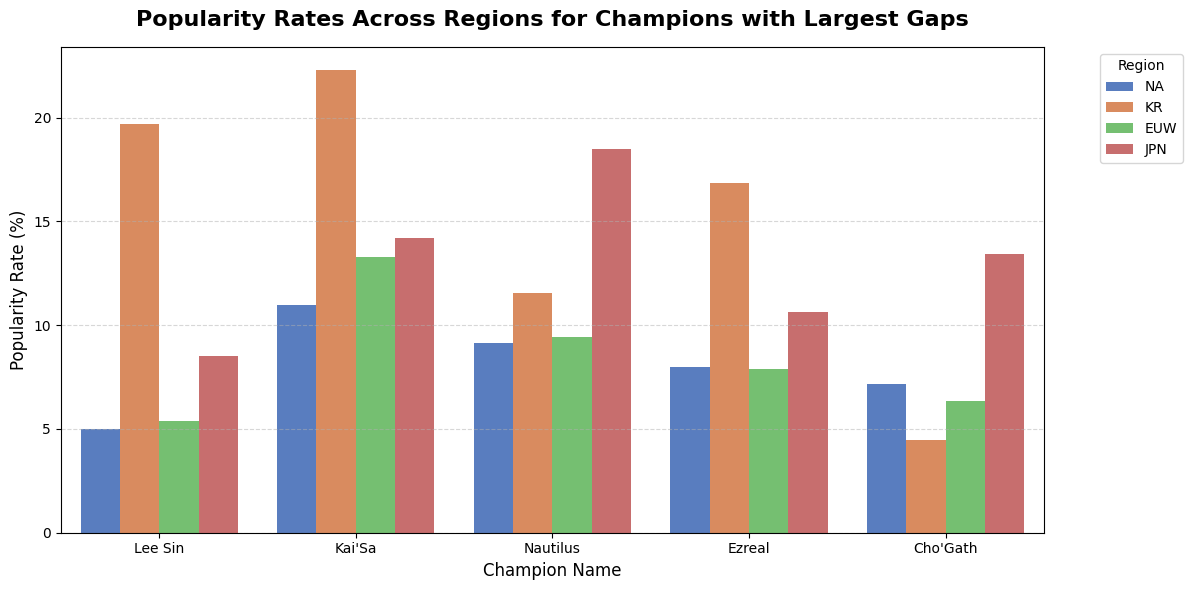

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get the names of the top 5 champions with largest gaps
top_5_names = gap_df['Champion Name'].tolist()

# Filter our cleaned dataset for these 5 champions
df_top_gaps = df_corr[df_corr['Champion Name'].isin(top_5_names)].copy()

# Melt the dataframe so we can easily plot it with seaborn
regions_melt = pd.melt(
    df_top_gaps,
    id_vars=['Champion Name'],
    value_vars=['PR (NA)', 'PR (KR)', 'PR (EUW)', 'PR (JPN)'],
    var_name='Region',
    value_name='Popularity Rate (%)'
)

# Clean region names for better legend labeling
regions_melt['Region'] = regions_melt['Region'].str.extract(r'\((.*?)\)')

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Champion Name',
    y='Popularity Rate (%)',
    hue='Region',
    data=regions_melt,
    order=top_5_names,
    palette='muted'
)

plt.title('Popularity Rates Across Regions for Champions with Largest Gaps', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Champion Name', fontsize=12)
plt.ylabel('Popularity Rate (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [21]:
# Define the regions we want to calculate correlations for
regions_list = ['Global', 'NA', 'KR', 'EUW', 'JPN']

regional_correlations = {}

# Calculate the correlation between WR and PR for each individual region
for r in regions_list:
    wr_col = f'WR ({r})'
    pr_col = f'PR ({r})'
    if wr_col in df_corr.columns and pr_col in df_corr.columns:
        corr_value = df_corr[wr_col].corr(df_corr[pr_col])
        regional_correlations[r] = corr_value

# Display the results
corr_df = pd.DataFrame(list(regional_correlations.items()), columns=['Region', 'Correlation (WR vs PR)'])
print("=== Correlation Between Win Rate and Popularity Rate by Region ===")
display(corr_df)

=== Correlation Between Win Rate and Popularity Rate by Region ===


,Region,Correlation (WR vs PR)
0,Global,0.132323
1,NA,0.301473
2,KR,-0.034799
3,EUW,0.112048
4,JPN,0.191004
